# 14 — Power with RAPL and IPMI on the flat-mode node: server socket, idle, HBM vs DDR

**Objective.** Measure the power of the vLLM server at the boundary that matters (the server socket) instead of the whole node, compare the two
meters available on CRESCO8, and find out what the on-package HBM contributes to power and energy per token.

**Research questions.**
1. Do RAPL and the BMC (IPMI) agree, and how does "IPMI minus idle" compare with the RAPL power of the server socket?
2. Where does the power go (server package, server DDR, client socket, platform) with the server's memory on HBM and on DDR?
3. What is the energy per output token at the server socket and at the node, absolute and above idle, on HBM and on DDR?

**Data.** Campaign `power-flat-20261019` (Slurm job 5418606, cresco8-hbm14, 2026-10-19; `scripts/benchmark/power_flat.py`, configs/experiment.toml
`[power_flat]`). The node is in **flat mode**: the HBM of each socket is a memory-only NUMA node (node 2 for socket 0). One job ran a 15-minute idle
baseline, vLLM BF16 decode (128→512) at C = 1, 16, 64, 128 with the server's memory on HBM (`numactl --membind=2`, NUMA shim), the same with memory on
DDR (`--membind=0`), and a 5-minute closing idle. Cores 0–54 (+55 front end) on socket 0, load client on socket 1, three repetitions per point. The
admins granted passwordless sudo on this node for `turbostat` and `ipmitool sensor` (and later `perf stat`).
- **RAPL** (`turbostat`, 1 s, per package): package power (cores, uncore and the on-package HBM; there is no separate HBM domain) and DRAM power (DDR5).
- **BMC** (`ipmitool sensor`, one read every ~6 s): Sys Power (whole node), CPU Power and Mem Power (both sockets), in 5–10 W steps.
- Processed table `power_phases.csv`: means per idle window and per repetition (steady window), from `data/raw/telemetry/online/power-flat-20261019/`.

**Method.** The server socket is package 0 + DRAM 0. "Above idle" subtracts the settled idle level (the last 10 minutes of the opening idle) domain by
domain. J per output token = power ÷ steady output tok/s of the same repetitions. The platform part is Sys − (CPU + Mem) of the BMC.

**Caveats up front.** Flat mode is not our primary memory mode (cache), so absolute throughput differs from notebooks 04–13; one node, one pass (HBM
then DDR); RAPL is the processor's own energy reporting, checked here against the BMC.

In [1]:
import json

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots

from llm_backend_analysis import paths
from llm_backend_analysis.analysis import power
from llm_backend_analysis.data import loaders, registry
from llm_backend_analysis.reporting import Claim, claims_table, export_table, num, pct, rng, show, table, x
from llm_backend_analysis.visualization import theme
from llm_backend_analysis.visualization.export import export_figure

theme.setup_notebook()
NOTEBOOK = "14_power_rapl_ipmi.ipynb"
ph = loaders.power_phases(power.CAMPAIGN)
pts = loaders.online_points(power.CAMPAIGN, include_variants=True)
run = json.loads(next((paths.RAW / "power" / power.CAMPAIGN).glob("run-*.json")).read_text())
idle = power.idle_levels(ph)
pp = power.point_power(ph, pts)
KEYS = []


def key(name, values, fmt, description):
    v = pd.Series(values, dtype=float).dropna()
    KEYS.append({"key": name, "text": rng(v, fmt) if len(v) else "–", "low": v.min(), "high": v.max(), "n": len(v), "description": description})


def ratio(v):
    return x(v, 2)

## 1. Was the run what it claims to be?

In [2]:
place = pd.DataFrame([{"memory node": r["node"], "placement": power.PLACEMENTS[f"vllm-bf16__{r['tag']}"], "C": p["concurrency"], "status": p["status"],
                       "share of server memory on that node": p["share_on_node"]} for r in run["runs"] for p in r["points"]])
display(table(place, {"share of server memory on that node": "{:.1%}"}, align="left"))
st = ph[ph["window"] == "steady"]
show(f"Preflight problems: {len(run['preflight_problems'])}. All {len(place)} points finished with status `ok`, with "
     f"{rng(place['share of server memory on that node'], lambda v: pct(v, 1, False))} of the server's memory on the requested node (numastat). "
     f"Each repetition's steady window holds {rng(st['rapl_n'])} RAPL intervals and {rng(st['ipmi_n'])} BMC reads; steady windows last "
     f"{rng(st['duration_s'])} s.")

memory node,placement,C,status,share of server memory on that node
2,HBM (node 2),1,ok,99.9%
2,HBM (node 2),16,ok,99.9%
2,HBM (node 2),64,ok,99.9%
2,HBM (node 2),128,ok,99.9%
0,DDR (node 0),1,ok,100.0%
0,DDR (node 0),16,ok,100.0%
0,DDR (node 0),64,ok,100.0%
0,DDR (node 0),128,ok,100.0%


Preflight problems: 0. All 8 points finished with status `ok`, with 99.9%–100.0% of the server's memory on the requested node (numastat). Each repetition's steady window holds 51–291 RAPL intervals and 7–45 BMC reads; steady windows last 52–292 s.

## 2. Idle levels

The opening idle window starts right after the job's STREAM node check, whose heat and raised uncore clock fade within about two minutes; the
first five minutes are left out ("settled"). The closing idle window checks for drift over the 2.4 h job.

In [3]:
idl = ph[ph["window"] == "idle"].set_index("phase").loc[["idle-start", power.IDLE_PHASE, "idle-end"]]
cols = {"duration_s": "Duration (s)", "rapl_pkg0_w": "Package 0 (W)", "rapl_ram0_w": "DRAM 0 (W)", "rapl_pkg1_w": "Package 1 (W)", "rapl_ram1_w": "DRAM 1 (W)",
        "ipmi_cpu_w": "BMC CPU (W)", "ipmi_mem_w": "BMC Mem (W)", "ipmi_sys_w": "BMC Sys (W)", "rapl_unc0_mhz": "Uncore 0 (MHz)", "slurm_node_w": "Slurm node (W)"}
display(table(idl[list(cols)].rename(columns=cols).reset_index().rename(columns={"phase": "Window"}), {c: "{:.1f}" for c in cols.values()}, align="left"))
drift = idl.loc["idle-end", "ipmi_sys_w"] / idl.loc[power.IDLE_PHASE, "ipmi_sys_w"] - 1
show(f"Settled idle: the server socket draws {num(idle['server_w'])} W (package {num(idle['pkg0'])} W, DDR {num(idle['ram0'])} W), the client socket "
     f"{num(idle['client_w'])} W, the platform outside both sockets {num(idle['platform_w'])} W; the node {num(idle['sys'])} W. A Xeon Max package idles at "
     f"about {pct(idle['pkg0'] / power.POWER_LIMIT_W, 0, False)} of its 350 W limit. The closing idle differs from the opening one by {pct(drift, 1)} at the node.")
key("power_idle_server_socket_w", [idle["server_w"]], num, "Idle server socket (RAPL package 0 + DRAM 0), W, settled opening idle, cresco8-hbm14 flat mode")
key("power_idle_node_w", [idle["sys"]], num, "Idle node (BMC Sys Power), W, settled opening idle")
key("power_idle_platform_w", [idle["platform_w"]], num, "Idle platform outside sockets and DRAM (BMC Sys − CPU − Mem), W")

Window,Duration (s),Package 0 (W),DRAM 0 (W),Package 1 (W),DRAM 1 (W),BMC CPU (W),BMC Mem (W),BMC Sys (W),Uncore 0 (MHz),Slurm node (W)
idle-start,910.8,136.2,20.9,134.2,19.1,270.4,40.1,398.7,810.9,404.7
idle-start-settled,610.8,135.5,21.0,134.2,19.1,270.0,40.1,398.1,800.0,–
idle-end,310.4,136.6,21.1,134.3,19.1,271.1,40.1,403.4,818.4,365.3


Settled idle: the server socket draws 156 W (package 136 W, DDR 21 W), the client socket 153 W, the platform outside both sockets 88 W; the node 398 W. A Xeon Max package idles at about 39% of its 350 W limit. The closing idle differs from the opening one by +1.3% at the node.

## 3. Do the two meters agree?

The BMC's CPU Power and Mem Power can be compared with the RAPL sums of both packages and both DRAM domains over the same windows (windows with at
least three BMC reads). Sys Power has no RAPL counterpart; Slurm's energy counter (IPMI DCMI, 60 s updates, read at each repetition's start and end)
is a third view of the node.

In [4]:
ma = power.meter_agreement(ph)
show(f"Over {len(ma)} windows, BMC CPU Power − RAPL (package 0 + 1) = {rng(ma['cpu_diff_w'], lambda v: num(v, 1))} W (mean {num(ma['cpu_diff_w'].mean(), 1)} W), "
     f"BMC Mem Power − RAPL (DRAM 0 + 1) = {rng(ma['mem_diff_w'], lambda v: num(v, 1))} W (mean {num(ma['mem_diff_w'].mean(), 2)} W). "
     "The BMC's CPU and Mem sensors are therefore the RAPL counters read out-of-band (in coarser steps), not independent meters; only Sys Power adds information.")
rep = ph[(ph["window"] == "rep") & ph["slurm_node_w"].notna()]
sl = rep.groupby("arm_dir").apply(lambda g: pd.Series({"slurm_w": np.average(g["slurm_node_w"], weights=g["duration_s"]),
                                                      "sys_w": np.average(g["ipmi_sys_w"], weights=g["duration_s"]), "seconds": g["duration_s"].sum()}),
                                  include_groups=False)
sl["slurm_over_sys"] = sl["slurm_w"] / sl["sys_w"]
display(table(sl.rename(index=power.PLACEMENTS).reset_index().rename(columns={"arm_dir": "Placement", "slurm_w": "Slurm node (W)", "sys_w": "BMC Sys (W)",
                                                                              "seconds": "Repetition time (s)", "slurm_over_sys": "Slurm ÷ BMC Sys"}),
              {"Slurm node (W)": "{:.0f}", "BMC Sys (W)": "{:.0f}", "Repetition time (s)": "{:.0f}", "Slurm ÷ BMC Sys": "{:.2f}"}, align="left"))
show(f"At idle the Slurm counter ({num(idl.loc['idle-start', 'slurm_node_w'])} W over the opening window) agrees with BMC Sys Power ({num(idl.loc['idle-start', 'ipmi_sys_w'])} W). "
     f"Under load it reads {rng(sl['slurm_over_sys'], lambda v: num(v, 2))} of Sys Power, summed over all repetitions of a placement. Repetitions last one to five "
     "minutes, so the 60 s update interval of the Slurm counter is a large part of each window; the node figures of notebook 13 (Slurm counter, cache mode) "
     "may be low by a similar factor. Open item.")
key("power_meter_cpu_diff_w", ma["cpu_diff_w"], lambda v: num(v, 1), "BMC CPU Power − RAPL package 0 + 1 (W), every window with ≥ 3 BMC reads")
key("power_meter_mem_diff_w", ma["mem_diff_w"], lambda v: num(v, 1), "BMC Mem Power − RAPL DRAM 0 + 1 (W), every window with ≥ 3 BMC reads")
key("power_slurm_over_bmc_sys_load", sl["slurm_over_sys"], lambda v: num(v, 2), "Slurm node energy rate ÷ BMC Sys Power over the repetitions of each placement")

Over 51 windows, BMC CPU Power − RAPL (package 0 + 1) = -7.7–11.3 W (mean 1.2 W), BMC Mem Power − RAPL (DRAM 0 + 1) = -1.9–1.0 W (mean 0.01 W). The BMC's CPU and Mem sensors are therefore the RAPL counters read out-of-band (in coarser steps), not independent meters; only Sys Power adds information.

Placement,Slurm node (W),BMC Sys (W),Repetition time (s),Slurm ÷ BMC Sys
DDR (node 0),650,731,3083,0.89
HBM (node 2),560,680,2229,0.82


At idle the Slurm counter (405 W over the opening window) agrees with BMC Sys Power (399 W). Under load it reads 0.82–0.89 of Sys Power, summed over all repetitions of a placement. Repetitions last one to five minutes, so the 60 s update interval of the Slurm counter is a large part of each window; the node figures of notebook 13 (Slurm counter, cache mode) may be low by a similar factor. Open item.

## 4. Where the power goes, HBM vs DDR

Steady-window means per point (three repetitions). Server package = RAPL package 0 (includes the HBM); server DDR = DRAM 0; client socket = package 1 + DRAM 1;
platform = BMC Sys − CPU − Mem.

In [5]:
cols = {"placement": "Placement", "concurrency": "C", "output_tok_s": "Output tok/s", "pkg0": "Server package (W)", "ram0": "Server DDR (W)", "client_w": "Client socket (W)",
        "platform_w": "Platform (W)", "sys": "Node, BMC (W)", "ghz_core": "Core clock (GHz)", "unc_mhz": "Uncore (MHz)", "pkg0_tmp_c": "Package temp (°C)"}
display(table(pp[list(cols)].rename(columns=cols), {"Output tok/s": "{:.1f}", **{c: "{:.1f}" for c in list(cols.values())[4:8]}, "Server package (W)": "{:.1f}",
                                                    "Core clock (GHz)": "{:.2f}", "Uncore (MHz)": "{:.0f}", "Package temp (°C)": "{:.0f}"}, align="left"))
h, d = pp[pp["arm_dir"] == "vllm-bf16__mem2"], pp[pp["arm_dir"] == "vllm-bf16__mem0"]
show(f"**The server package runs at its power limit at every point**: {rng(pp['pkg0'], lambda v: num(v, 1))} W against the 350 W limit, on HBM and on DDR, "
     f"from C = 1 to C = 128. vLLM keeps all 55 compute cores busy even for one request, so the socket's power does not follow the load; the processor "
     f"lowers its clock instead ({rng(pp['ghz_core'], lambda v: num(v, 2))} GHz). What changes with the placement is the DDR: with the server's memory on HBM "
     f"the server's DDR stays at idle ({rng(h['ram0'], lambda v: num(v, 1))} W against {num(idle['ram0'], 1)} W idle), on DDR it draws "
     f"{rng(d['ram0'], lambda v: num(v, 1))} W. The client socket draws {rng(pp['client_w'])} W (idle {num(idle['client_w'])} W), the platform "
     f"{rng(pp['platform_w'])} W (idle {num(idle['platform_w'])} W, fans and regulators follow the load).")
key("power_server_package_load_w", pp["pkg0"], lambda v: num(v, 1), "Server package (RAPL package 0, incl. HBM) under load, every point, HBM and DDR placement (W); limit 350 W")
key("power_server_ddr_hbm_w", h["ram0"], lambda v: num(v, 1), "Server DDR (RAPL DRAM 0) with the server's memory on HBM (W)")
key("power_server_ddr_ddr_w", d["ram0"], lambda v: num(v, 1), "Server DDR (RAPL DRAM 0) with the server's memory on DDR (W)")
key("power_node_load_w", pp["sys"], num, "Node power under load (BMC Sys Power), every point (W)")
key("power_core_ghz", pp["ghz_core"], lambda v: num(v, 2), "Effective core clock under load (telemetry), every point (GHz)")

Placement,C,Output tok/s,Server package (W),Server DDR (W),Client socket (W),Platform (W),"Node, BMC (W)",Core clock (GHz),Uncore (MHz),Package temp (°C)
HBM (node 2),1,22.0,349.5,21.6,185.7,110.4,668.6,2.31,1732,53
HBM (node 2),16,303.9,349.3,21.7,184.6,114.6,670.8,2.21,1704,52
HBM (node 2),64,710.6,349.0,21.9,187.7,127.9,687.1,2.11,1732,50
HBM (node 2),128,755.2,349.4,22.1,187.9,129.1,687.3,2.02,1742,49
DDR (node 0),1,14.0,349.4,63.8,195.8,124.1,733.0,2.51,1929,49
DDR (node 0),16,199.1,349.3,61.7,195.6,124.2,733.3,2.39,1906,50
DDR (node 0),64,537.3,349.4,55.2,203.2,127.3,737.4,2.12,1982,49
DDR (node 0),128,613.4,349.3,49.0,196.7,129.0,726.3,2.11,1919,50


**The server package runs at its power limit at every point**: 349.0–349.5 W against the 350 W limit, on HBM and on DDR, from C = 1 to C = 128. vLLM keeps all 55 compute cores busy even for one request, so the socket's power does not follow the load; the processor lowers its clock instead (2.02–2.51 GHz). What changes with the placement is the DDR: with the server's memory on HBM the server's DDR stays at idle (21.6–22.1 W against 21.0 W idle), on DDR it draws 49.0–63.8 W. The client socket draws 185–203 W (idle 153 W), the platform 110–129 W (idle 88 W, fans and regulators follow the load).

## 5. RAPL of the server socket vs IPMI minus idle

The colleague's question: does "node power minus idle node power" (what IPMI alone can give) measure the server? Both are taken over the same windows.

In [6]:
cmp_ = pp[["placement", "concurrency", "server_above_idle_w", "sys_above_idle_w", "client_above_idle_w", "platform_above_idle_w"]].copy()
cmp_["ipmi_over_rapl"] = cmp_["sys_above_idle_w"] / cmp_["server_above_idle_w"]
cmp_["unexplained_w"] = cmp_["sys_above_idle_w"] - cmp_["server_above_idle_w"] - cmp_["client_above_idle_w"] - cmp_["platform_above_idle_w"]
cols = {"placement": "Placement", "concurrency": "C", "server_above_idle_w": "Server socket above idle, RAPL (W)", "sys_above_idle_w": "Node above idle, BMC (W)",
        "client_above_idle_w": "of which client socket (W)", "platform_above_idle_w": "of which platform (W)", "ipmi_over_rapl": "BMC ÷ RAPL"}
display(table(cmp_[list(cols)].rename(columns=cols), {**{c: "{:.0f}" for c in list(cols.values())[2:6]}, "BMC ÷ RAPL": "{:.2f}"}, align="left"))
show(f"Above idle, the server socket adds {rng(cmp_['server_above_idle_w'])} W (RAPL); the node adds {rng(cmp_['sys_above_idle_w'])} W (BMC), "
     f"{rng(cmp_['ipmi_over_rapl'], lambda v: num(v, 2))} times as much. The difference is the client socket ({rng(cmp_['client_above_idle_w'])} W above its idle: load client, "
     f"telemetry, meters) and the platform ({rng(cmp_['platform_above_idle_w'])} W: fans and regulators); the remainder is {rng(cmp_['unexplained_w'], lambda v: num(v, 1))} W. "
     f"So IPMI minus idle overstates the server's own added power by {rng(cmp_['ipmi_over_rapl'] - 1, lambda v: pct(v, 0, False))}; it is the right figure for "
     "\"what the whole machine adds\", RAPL of package 0 + DRAM 0 is the right figure for the server.")
key("power_server_above_idle_w", cmp_["server_above_idle_w"], num, "Server socket above idle (RAPL package 0 + DRAM 0 − idle), W, every point")
key("power_node_above_idle_w", cmp_["sys_above_idle_w"], num, "Node above idle (BMC Sys − idle Sys), W, every point")
key("power_ipmi_over_rapl_above_idle", cmp_["ipmi_over_rapl"], lambda v: num(v, 2), "Node above idle (BMC) ÷ server socket above idle (RAPL)")

Placement,C,"Server socket above idle, RAPL (W)","Node above idle, BMC (W)",of which client socket (W),of which platform (W),BMC ÷ RAPL
HBM (node 2),1,215,270,32,22,1.26
HBM (node 2),16,214,273,31,27,1.27
HBM (node 2),64,214,289,34,40,1.35
HBM (node 2),128,215,289,35,41,1.35
DDR (node 0),1,257,335,43,36,1.30
DDR (node 0),16,254,335,42,36,1.32
DDR (node 0),64,248,339,50,39,1.37
DDR (node 0),128,242,328,43,41,1.36


Above idle, the server socket adds 214–257 W (RAPL); the node adds 270–339 W (BMC), 1.26–1.37 times as much. The difference is the client socket (31–50 W above its idle: load client, telemetry, meters) and the platform (22–41 W: fans and regulators); the remainder is -1.6–2.2 W. So IPMI minus idle overstates the server's own added power by 26%–37%; it is the right figure for "what the whole machine adds", RAPL of package 0 + DRAM 0 is the right figure for the server.

## 6. Energy per output token

Four boundaries, from the narrowest to the widest: server socket above idle, server socket, node above idle, node.

Placement,C,Output tok/s,Server above idle (J/tok),Server socket (J/tok),Node above idle (J/tok),Node (J/tok)
HBM (node 2),1,22.0,9.752,16.860,12.286,30.370
HBM (node 2),16,303.9,0.706,1.221,0.897,2.207
HBM (node 2),64,710.6,0.302,0.522,0.407,0.967
HBM (node 2),128,755.2,0.285,0.492,0.383,0.910
DDR (node 0),1,14.0,18.315,29.477,23.891,52.288
DDR (node 0),16,199.1,1.278,2.064,1.683,3.683
DDR (node 0),64,537.3,0.462,0.753,0.631,1.372
DDR (node 0),128,613.4,0.394,0.649,0.535,1.184


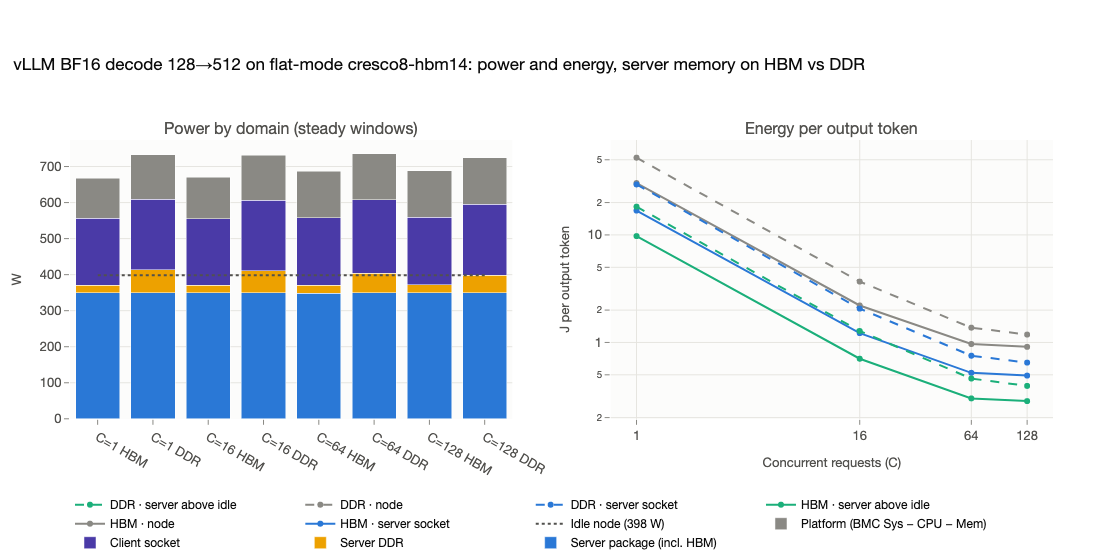

Server-socket energy per token falls from 16.9 J at C = 1 to 0.49 J at C = 128 on HBM (29.5 → 0.65 J on DDR): the power is fixed by the package limit, so energy per token is the inverse of throughput. The node figure is 1.77–1.85 times the server-socket figure.

In [7]:
cols = {"placement": "Placement", "concurrency": "C", "output_tok_s": "Output tok/s", "j_per_token_server_above_idle": "Server above idle (J/tok)",
        "j_per_token_server": "Server socket (J/tok)", "j_per_token_node_above_idle": "Node above idle (J/tok)", "j_per_token_node": "Node (J/tok)"}
display(table(pp[list(cols)].rename(columns=cols), {"Output tok/s": "{:.1f}", **{c: "{:.3f}" for c in list(cols.values())[3:]}}, align="left"))
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1, subplot_titles=("Power by domain (steady windows)", "Energy per output token"))
parts = [("pkg0", "Server package (incl. HBM)", theme.BACKEND_COLORS["vllm"]), ("ram0", "Server DDR", theme.EXTRA_COLORS[2]),
         ("client_w", "Client socket", theme.EXTRA_COLORS[1]), ("platform_w", "Platform (BMC Sys − CPU − Mem)", theme.TEXT_MUTED)]
xcat = [f"C={c} {'HBM' if a.endswith('mem2') else 'DDR'}" for a, c in zip(pp["arm_dir"], pp["concurrency"])]
order = [f"C={c} {m}" for c in sorted(pp["concurrency"].unique()) for m in ("HBM", "DDR")]
idx = [xcat.index(o) for o in order]
for col, name, color in parts:
    fig.add_trace(go.Bar(x=order, y=pp[col].to_numpy()[idx], name=name, marker_color=color), row=1, col=1)
fig.add_trace(go.Scatter(x=order, y=[idle["sys"]] * len(order), mode="lines", name=f"Idle node ({num(idle['sys'])} W)",
                         line=dict(color=theme.REFERENCE, dash="dot")), row=1, col=1)
for a, dash in (("vllm-bf16__mem2", "solid"), ("vllm-bf16__mem0", "dash")):
    g = pp[pp["arm_dir"] == a]
    for colname, label, color in (("j_per_token_server", "server socket", theme.BACKEND_COLORS["vllm"]), ("j_per_token_node", "node", theme.TEXT_MUTED),
                                  ("j_per_token_server_above_idle", "server above idle", theme.EXTRA_COLORS[0])):
        fig.add_trace(go.Scatter(x=g["concurrency"], y=g[colname], mode="lines+markers", name=f"{power.PLACEMENTS[a].split()[0]} · {label}",
                                 line=dict(color=color, dash=dash), marker=dict(color=color)), row=1, col=2)
fig.update_layout(barmode="stack", height=560, title="vLLM BF16 decode 128→512 on flat-mode cresco8-hbm14: power and energy, server memory on HBM vs DDR",
                  legend=dict(orientation="h", y=-0.22))
fig.update_yaxes(title_text="W", row=1, col=1)
fig.update_xaxes(type="log", title_text="Concurrent requests (C)", tickvals=[1, 16, 64, 128], row=1, col=2)
fig.update_yaxes(type="log", title_text="J per output token", row=1, col=2)
fig.show()
export_figure(fig, "power_hbm_ddr_breakdown", source=NOTEBOOK, width=1300,
              caption="vLLM BF16 decode 128→512 on cresco8-hbm14 (flat mode), server memory on HBM (node 2) or DDR (node 0): left, steady-state power by domain "
                      "(RAPL package 0 incl. HBM, RAPL DRAM 0, client socket, platform from the BMC) with the idle node level; right, J per output token at the "
                      "server socket, above idle, and at the node.")
show(f"Server-socket energy per token falls from {num(h['j_per_token_server'].iloc[0], 1)} J at C = 1 to {num(h['j_per_token_server'].iloc[-1], 2)} J at C = 128 on HBM "
     f"({num(d['j_per_token_server'].iloc[0], 1)} → {num(d['j_per_token_server'].iloc[-1], 2)} J on DDR): the power is fixed by the package limit, so energy per token is the "
     f"inverse of throughput. The node figure is {rng(pp['j_per_token_node'] / pp['j_per_token_server'], lambda v: num(v, 2))} times the server-socket figure.")
key("power_j_per_token_server_hbm", h["j_per_token_server"], lambda v: num(v, 2), "J per output token at the server socket (RAPL package 0 + DRAM 0), HBM placement, C = 1…128")
key("power_j_per_token_server_ddr", d["j_per_token_server"], lambda v: num(v, 2), "J per output token at the server socket, DDR placement, C = 1…128")
key("power_j_per_token_server_above_idle_hbm", h["j_per_token_server_above_idle"], lambda v: num(v, 2), "J per output token, server socket above idle, HBM placement")
key("power_j_per_token_node_hbm", h["j_per_token_node"], lambda v: num(v, 2), "J per output token at the node (BMC Sys), HBM placement")

## 7. What does the HBM contribute?

No meter reports the HBM separately: it sits inside the package domain. The A/B gives its effect: same cores, same package limit, memory on HBM or on DDR.

In [8]:
hd = power.hbm_vs_ddr(pp)
cols = {"concurrency": "C", "throughput_ratio": "Throughput HBM ÷ DDR", "server_j_ratio": "Server J/tok HBM ÷ DDR", "node_j_ratio": "Node J/tok HBM ÷ DDR",
        "delta_pkg0": "Δ package (W)", "delta_ram0": "Δ server DDR (W)", "delta_client_w": "Δ client socket (W)", "delta_platform_w": "Δ platform (W)",
        "delta_sys": "Δ node (W)", "ghz_hbm": "Core GHz, HBM", "ghz_ddr": "Core GHz, DDR", "delta_unc_mhz": "Δ uncore (MHz)"}
display(table(hd[list(cols)].rename(columns=cols), {**{c: "{:.2f}" for c in list(cols.values())[1:4]}, **{c: "{:.1f}" for c in list(cols.values())[4:9]},
                                                    "Core GHz, HBM": "{:.2f}", "Core GHz, DDR": "{:.2f}", "Δ uncore (MHz)": "{:.0f}"}, align="left"))
show(f"Moving the server's memory from DDR to HBM raises throughput by {rng(hd['throughput_ratio'] - 1, lambda v: pct(v, 0))} (most at C = 1, where decode streams "
     f"the weights) and lowers the server-socket energy per token to {rng(hd['server_j_ratio'], lambda v: num(v, 2))} of the DDR value. The package power does not change "
     f"(Δ {rng(hd['delta_pkg0'], lambda v: num(v, 1))} W, it is at its limit in both cases), the DDR saves {rng(-hd['delta_ram0'], lambda v: num(v, 0))} W and the node "
     f"{rng(-hd['delta_sys'])} W. Inside the fixed package budget the HBM's share shows indirectly: with memory on HBM the cores run "
     f"{rng((hd['ghz_ddr'] - hd['ghz_hbm'])[hd['concurrency'] <= 16], lambda v: num(v, 2))} GHz slower at C ≤ 16 "
     f"({rng((hd['ghz_ddr'] - hd['ghz_hbm'])[hd['concurrency'] > 16], lambda v: num(v, 2))} GHz at C ≥ 64) and the uncore {rng(-hd['delta_unc_mhz'])} MHz slower, i.e. HBM traffic takes part "
     "of the 350 W that would otherwise go to the cores (inferred; there is no HBM power counter).")
key("power_hbm_over_ddr_throughput", hd["throughput_ratio"], ratio, "Output tok/s, server memory on HBM ÷ on DDR (flat mode, same cores), C = 1…128")
key("power_hbm_over_ddr_server_j", hd["server_j_ratio"], lambda v: num(v, 2), "Server-socket J per output token, HBM ÷ DDR")
key("power_ddr_saving_w", -hd["delta_ram0"], num, "Server DDR power saved when the server's memory is on HBM (W)")
key("power_node_saving_w", -hd["delta_sys"], num, "Node power saved when the server's memory is on HBM (W)")

C,Throughput HBM ÷ DDR,Server J/tok HBM ÷ DDR,Node J/tok HBM ÷ DDR,Δ package (W),Δ server DDR (W),Δ client socket (W),Δ platform (W),Δ node (W),"Core GHz, HBM","Core GHz, DDR",Δ uncore (MHz)
1,1.57,0.57,0.58,0.1,-42.2,-10.1,-13.7,-64.5,2.31,2.51,-197
16,1.53,0.59,0.60,0.0,-40.0,-11.0,-9.6,-62.5,2.21,2.39,-202
64,1.32,0.69,0.70,-0.4,-33.3,-15.5,0.7,-50.3,2.11,2.12,-250
128,1.23,0.76,0.77,0.0,-26.9,-8.8,0.1,-39.0,2.02,2.11,-178


Moving the server's memory from DDR to HBM raises throughput by +23%–+57% (most at C = 1, where decode streams the weights) and lowers the server-socket energy per token to 0.57–0.76 of the DDR value. The package power does not change (Δ -0.4–0.1 W, it is at its limit in both cases), the DDR saves 27–42 W and the node 39–64 W. Inside the fixed package budget the HBM's share shows indirectly: with memory on HBM the cores run 0.18–0.20 GHz slower at C ≤ 16 (0.01–0.09 GHz at C ≥ 64) and the uncore 178–250 MHz slower, i.e. HBM traffic takes part of the 350 W that would otherwise go to the cores (inferred; there is no HBM power counter).

## 8. Relation to the cache-mode results

Notebooks 04–13 use cache mode (HBM as a memory-side cache in front of DDR) on other nodes. Same decode shape, same layout:

In [9]:
m = loaders.online_points("main", model=registry.primary_model())
m = m[(m["configuration_id"] == "vllm_bf16") & (m["workload"] == "decode") & m["concurrency"].isin(sorted(pp["concurrency"].unique()))].set_index("concurrency")
cm = h.set_index("concurrency")[["output_tok_s", "ghz_core"]].join(d.set_index("concurrency")[["output_tok_s"]], rsuffix="_ddr").join(
    m[["output_tok_s_mean", "ghz_effective_per_core_mean"]])
cm["flat_hbm_over_cache"] = cm["output_tok_s"] / cm["output_tok_s_mean"]
display(table(cm.reset_index().rename(columns={"concurrency": "C", "output_tok_s": "Flat, HBM (tok/s)", "output_tok_s_ddr": "Flat, DDR (tok/s)",
                                               "output_tok_s_mean": "Cache mode (tok/s)", "ghz_core": "Flat HBM GHz", "ghz_effective_per_core_mean": "Cache GHz",
                                               "flat_hbm_over_cache": "Flat HBM ÷ cache"}),
              {"Flat, HBM (tok/s)": "{:.1f}", "Flat, DDR (tok/s)": "{:.1f}", "Cache mode (tok/s)": "{:.1f}", "Flat HBM GHz": "{:.2f}", "Cache GHz": "{:.2f}",
               "Flat HBM ÷ cache": "{:.2f}"}, align="left"))
show(f"With the weights and KV cache entirely in HBM (flat mode) vLLM delivers {rng(cm['flat_hbm_over_cache'], lambda v: num(v, 2))} times its cache-mode throughput at the "
     f"same C (different nodes and days). The package limit applies in both modes, so the cache-mode node power of notebook 13 (Slurm, 647–712 W) is "
     "consistent with a server socket at its limit; its split by socket would need RAPL on a cache-mode node.")
key("power_flat_hbm_over_cache_throughput", cm["flat_hbm_over_cache"], lambda v: num(v, 2), "vLLM BF16 decode output tok/s: flat mode, memory on HBM (hbm14) ÷ cache mode (main campaign), same C")

C,"Flat, HBM (tok/s)",Flat HBM GHz,"Flat, DDR (tok/s)",Cache mode (tok/s),Cache GHz,Flat HBM ÷ cache
1,22.0,2.31,14.0,18.5,2.34,1.19
16,303.9,2.21,199.1,254.8,2.27,1.19
64,710.6,2.11,537.3,628.2,2.16,1.13
128,755.2,2.02,613.4,700.4,2.05,1.08


With the weights and KV cache entirely in HBM (flat mode) vLLM delivers 1.08–1.19 times its cache-mode throughput at the same C (different nodes and days). The package limit applies in both modes, so the cache-mode node power of notebook 13 (Slurm, 647–712 W) is consistent with a server socket at its limit; its split by socket would need RAPL on a cache-mode node.

## 9. Claims checked against the data

In [10]:
claims = [
    Claim("Every point has at least 90% of the server's memory on the requested node", bool((place["share of server memory on that node"] >= 0.9).all()),
          rng(place["share of server memory on that node"], lambda v: pct(v, 1, False))),
    Claim("The server package is within 1% of its 350 W limit at every load point", bool(((pp["pkg0"] / power.POWER_LIMIT_W - 1).abs() < 0.01).all()),
          f"{rng(pp['pkg0'], lambda v: num(v, 1))} W"),
    Claim("BMC CPU and Mem Power equal the RAPL sums within 12 W and 2 W in every window with ≥ 3 BMC reads",
          bool((ma["cpu_diff_w"].abs() <= 12).all() and (ma["mem_diff_w"].abs() <= 2).all()),
          f"CPU {rng(ma['cpu_diff_w'], lambda v: num(v, 1))} W, Mem {rng(ma['mem_diff_w'], lambda v: num(v, 1))} W"),
    Claim("With the server's memory on HBM the server DDR stays within 2 W of its idle level", bool(((h["ram0"] - idle["ram0"]).abs() < 2).all()),
          f"{rng(h['ram0'], lambda v: num(v, 1))} W vs {num(idle['ram0'], 1)} W"),
    Claim("Throughput is higher on HBM than on DDR at every C, and server-socket J/token lower", bool((hd["throughput_ratio"] > 1).all() and (hd["server_j_ratio"] < 1).all()),
          f"{rng(hd['throughput_ratio'], ratio)}, {rng(hd['server_j_ratio'], lambda v: num(v, 2))}"),
    Claim("Node above idle (BMC) exceeds server socket above idle (RAPL) at every point", bool((cmp_["ipmi_over_rapl"] > 1).all()),
          rng(cmp_["ipmi_over_rapl"], lambda v: num(v, 2))),
    Claim("Idle node power drifted by less than 2% over the job", bool(abs(drift) < 0.02), pct(drift, 1)),
]
display(claims_table(claims))
export_table(pp, "power_hbm_ddr_points")
export_table(hd, "power_hbm_vs_ddr")
export_table(pd.DataFrame(KEYS), "power_key_numbers")
display(table(pd.DataFrame(KEYS)[["key", "text", "description"]].rename(columns={"key": "Key", "text": "Value", "description": "Description"}), align="left",
              caption=f"Power key numbers ({len(KEYS)}; exported to power_key_numbers.csv)"))

Holds,Statement,Evidence (computed)
✓,Every point has at least 90% of the server's memory on the requested node,99.9%–100.0%
✓,The server package is within 1% of its 350 W limit at every load point,349.0–349.5 W
✓,BMC CPU and Mem Power equal the RAPL sums within 12 W and 2 W in every window with ≥ 3 BMC reads,"CPU -7.7–11.3 W, Mem -1.9–1.0 W"
✓,With the server's memory on HBM the server DDR stays within 2 W of its idle level,21.6–22.1 W vs 21.0 W
✓,"Throughput is higher on HBM than on DDR at every C, and server-socket J/token lower","1.23×–1.57×, 0.57–0.76"
✓,Node above idle (BMC) exceeds server socket above idle (RAPL) at every point,1.26–1.37
✓,Idle node power drifted by less than 2% over the job,+1.3%


Key,Value,Description
power_idle_server_socket_w,156,"Idle server socket (RAPL package 0 + DRAM 0), W, settled opening idle, cresco8-hbm14 flat mode"
power_idle_node_w,398,"Idle node (BMC Sys Power), W, settled opening idle"
power_idle_platform_w,88,"Idle platform outside sockets and DRAM (BMC Sys − CPU − Mem), W"
power_meter_cpu_diff_w,-7.7–11.3,"BMC CPU Power − RAPL package 0 + 1 (W), every window with ≥ 3 BMC reads"
power_meter_mem_diff_w,-1.9–1.0,"BMC Mem Power − RAPL DRAM 0 + 1 (W), every window with ≥ 3 BMC reads"
power_slurm_over_bmc_sys_load,0.82–0.89,Slurm node energy rate ÷ BMC Sys Power over the repetitions of each placement
power_server_package_load_w,349.0–349.5,"Server package (RAPL package 0, incl. HBM) under load, every point, HBM and DDR placement (W); limit 350 W"
power_server_ddr_hbm_w,21.6–22.1,Server DDR (RAPL DRAM 0) with the server's memory on HBM (W)
power_server_ddr_ddr_w,49.0–63.8,Server DDR (RAPL DRAM 0) with the server's memory on DDR (W)
power_node_load_w,669–737,"Node power under load (BMC Sys Power), every point (W)"


## Conclusions

- **The server socket can be measured on its own** on cresco8-hbm14: RAPL package 0 + DRAM 0. The BMC's CPU and Mem Power are the same RAPL counters read
  out-of-band, so the two meters agree by construction; the BMC's Sys Power is the only independent whole-node figure.
- **The server socket runs at its 350 W package limit at every load**, on HBM and on DDR, from one request to 128: vLLM's busy cores take the whole
  power budget and the processor trades clock for power. Energy per token is therefore set by throughput, not by a varying power.
- **IPMI minus idle is not the server's power**: it adds the client socket's work and the platform's response (fans, regulators), 26–37% more than the
  server socket's own increase measured with RAPL.
- **HBM vs DDR (flat mode):** HBM gives more throughput (most at C = 1) for the same package power and saves the DDR's 27–42 W, so the server-socket energy
  per token is 0.57–0.76 of the DDR value. HBM has no power counter of its own; its traffic shows as a lower core and uncore clock inside the fixed package
  budget (inferred).

## Limitations

- Flat mode on one node (cresco8-hbm14); the primary results are cache mode on other nodes. One pass (HBM, then DDR) with idle before and after; the
  drift check covers the idle level, not an order effect under load.
- RAPL is the processor's own model-and-sensor energy reporting; the BMC sensors that could check it are derived from it. Only Sys Power is independent.
- The Slurm energy counter reads below BMC Sys Power under load (section 3); notebook 13's node figures come from that counter.
- The HBM's own power is not measured; its effect is inferred from the A/B and the clocks.